# Do the best patterns make money as real trades?

The earlier analysis measured *forward returns* after a pattern. This notebook turns the five best daily patterns into **trades with costs**:

| Pattern | Direction |
|---|---|
| Double bottom | long |
| Three white soldiers | long |
| Rectangle breakout up | long |
| MACD bearish divergence | short |
| RSI bearish divergence | short |

**Trade rules**
- Signal on a daily close; **enter at the next day's open**.
- Exit on a stop-loss, a take-profit (both measured in ATR, the average daily range) or after a maximum holding time, whichever comes first. If one bar touches both stop and target, the **stop is assumed to hit first**.
- **Costs: 0.15% per side** (0.10% exchange fee + 0.05% slippage), so 0.30% per round trip. Shorts ignore funding costs.
- One open trade per coin and pattern. Equal size per trade; returns are log returns in %.
- The stop/target/holding time are **tuned only on trades entered before 2024**, then applied unchanged to 2024 onward.
- Universe: ETH, SOL, BNB, XRP, ADA, DOGE. Bitcoin is checked separately at the end.

**Important caveat.** These five patterns were chosen because they looked best in the 2024+ data in the previous notebook, so 2024+ is *not* a clean out-of-sample test for them. The honest evidence is: (a) does the result beat random entries with the same exit rules, (b) is it spread over years and coins, and (c) does it survive higher costs.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from cross_coin import COINS, prepare
from trade_sim import run_trades, trade_stats, tune_exit_rules, random_entry_baseline, DEFAULT_COST

TEST_START = '2024-01-01'
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = '#2a78d6', '#eb6834', '#1baf7a', '#c98500', '#d55181'
plt.rcParams.update({
    'figure.figsize': (11, 4.5), 'figure.dpi': 110, 'figure.facecolor': '#fcfcfb',
    'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#c3c2b7', 'axes.grid': True, 'axes.axisbelow': True,
    'grid.color': '#e6e5e0', 'grid.linewidth': 0.6, 'axes.spines.top': False,
    'axes.spines.right': False, 'lines.linewidth': 1.8, 'font.size': 10,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
})
pd.set_option('display.width', 220)

PATTERNS = [('double_bottom', 1), ('three_white_soldiers', 1), ('rectangle_up', 1),
            ('macd_bear_div', -1), ('rsi_bear_div', -1)]
COLORS = dict(zip([p for p, _ in PATTERNS], [BLUE, ORANGE, AQUA, YELLOW, MAGENTA]))
none_if_nan = lambda x: None if pd.isna(x) else float(x)

coins = prepare(COINS, 'daily', TEST_START)
print({s: len(c['ohlc']) for s, c in coins.items()})

{'ETHUSDT': 3208, 'SOLUSDT': 2255, 'BNBUSDT': 3208, 'XRPUSDT': 3085, 'ADAUSDT': 3102, 'DOGEUSDT': 2658}


## 1. Tune the exit rules on the earlier period only

Every combination of stop (none/1/2/3 ATR), target (none/2/3/4 ATR) and max hold (5/10/20 days) is tried on trades entered **before 2024**.
The combination with the best average net return per trade is kept. Shown: the top 3 for each pattern.

In [2]:
tuned = {}
rows = []
for pat, d in PATTERNS:
    g = tune_exit_rules(coins, pat, d, TEST_START, min_trades=25)
    tuned[pat] = g.iloc[0]
    top = g.head(3).copy(); top.insert(0, 'pattern', pat)
    rows.append(top)
top3 = pd.concat(rows).set_index(['pattern'])
top3[['stop', 'tgt', 'hold', 'n', 'win_rate', 'avg_net_pct', 'avg_gross_pct', 'profit_factor']].round(2)

,stop,tgt,hold,n,win_rate,avg_net_pct,avg_gross_pct,profit_factor
pattern,,,,,,,,
double_bottom,2.0,NaN,10,87,0.48,2.40,2.70,1.47
double_bottom,1.0,NaN,20,86,0.29,2.07,2.37,1.39
double_bottom,NaN,NaN,10,87,0.51,2.03,2.33,1.37
three_white_soldiers,NaN,NaN,20,44,0.68,13.54,13.84,3.09
three_white_soldiers,3.0,NaN,20,45,0.67,12.53,12.83,2.85
three_white_soldiers,2.0,NaN,20,45,0.58,11.77,12.07,2.93
rectangle_up,NaN,NaN,10,43,0.47,4.18,4.48,1.99
rectangle_up,3.0,4.0,10,43,0.53,4.13,4.43,2.03
rectangle_up,3.0,NaN,10,43,0.47,4.12,4.42,1.96


## 2. Results on 2024 onward, with the chosen rules

`naive` = hold 5 days, no stop, no target (the rule used in the earlier forward-return tests), for comparison.
**Random baseline**: the same number of trades per coin, entered on random days since 2024 in the same direction with the same exit rules.
`p-value` is how often the random entries did at least as well as the pattern.

In [3]:
trades, naive_trades, base_means, summary = {}, {}, {}, []
for pat, d in PATTERNS:
    r = tuned[pat]
    stop, tgt, hold = none_if_nan(r['stop']), none_if_nan(r['tgt']), int(r['hold'])
    t = run_trades(coins, pat, d, stop, tgt, hold)
    trades[pat] = t
    rec = t[t['entry'] >= TEST_START]
    nv = run_trades(coins, pat, d, None, None, 5)
    nv_rec = nv[nv['entry'] >= TEST_START]
    naive_trades[pat] = nv
    n_per_coin = rec.groupby('coin').size().to_dict()
    base = random_entry_baseline(coins, d, stop, tgt, hold, TEST_START, n_per_coin)
    base_means[pat] = base
    st = trade_stats(rec)
    obs = rec['net'].mean()
    summary.append({
        'pattern': pat, 'side': 'long' if d > 0 else 'short',
        'rules': f"stop {stop or '-'} / tgt {tgt or '-'} ATR, {hold}d",
        'trades': st['n'], 'win_rate': st['win_rate'], 'avg_net_%': st['avg_net_pct'],
        'avg_gross_%': st['avg_gross_pct'], 'profit_factor': st['profit_factor'],
        'worst_trade_%': st['worst_pct'],
        'random_avg_net_%': 100 * np.nanmean(base),
        'p_value': (np.sum(base >= obs) + 1) / (len(base) + 1),
        'naive_avg_net_%': trade_stats(nv_rec)['avg_net_pct'],
    })
summary = pd.DataFrame(summary).set_index('pattern')
summary.round(2)

,side,rules,trades,win_rate,avg_net_%,avg_gross_%,profit_factor,worst_trade_%,random_avg_net_%,p_value,naive_avg_net_%
pattern,,,,,,,,,,,
double_bottom,long,"stop 2.0 / tgt - ATR, 10d",47,0.51,3.69,3.99,1.91,-20.89,-0.64,0.01,3.02
three_white_soldiers,long,"stop - / tgt - ATR, 20d",43,0.42,3.82,4.12,1.61,-40.25,-0.01,0.09,1.47
rectangle_up,long,"stop - / tgt - ATR, 10d",34,0.50,4.19,4.49,2.13,-16.11,-0.14,0.03,2.19
macd_bear_div,short,"stop 1.0 / tgt 2.0 ATR, 20d",64,0.56,3.96,4.26,2.63,-9.88,0.34,0.00,2.58
rsi_bear_div,short,"stop 2.0 / tgt 2.0 ATR, 10d",44,0.61,3.60,3.90,2.18,-17.02,0.41,0.02,1.84


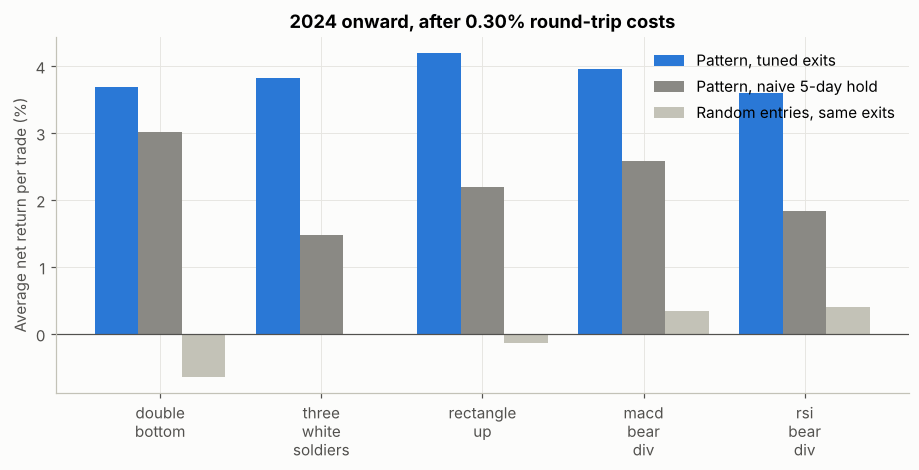

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(summary)); w = 0.27
ax.bar(x - w, summary['avg_net_%'], w, color=BLUE, label='Pattern, tuned exits')
ax.bar(x, summary['naive_avg_net_%'], w, color='#8a8984', label='Pattern, naive 5-day hold')
ax.bar(x + w, summary['random_avg_net_%'], w, color='#c3c2b7', label='Random entries, same exits')
ax.axhline(0, color='#52514e', lw=0.8)
ax.set_xticks(x); ax.set_xticklabels([p.replace('_', '\n') for p in summary.index])
ax.set_ylabel('Average net return per trade (%)')
ax.set_title('2024 onward, after 0.30% round-trip costs')
ax.legend(frameon=False)
plt.show()

## 3. Cumulative return of each strategy since 2024

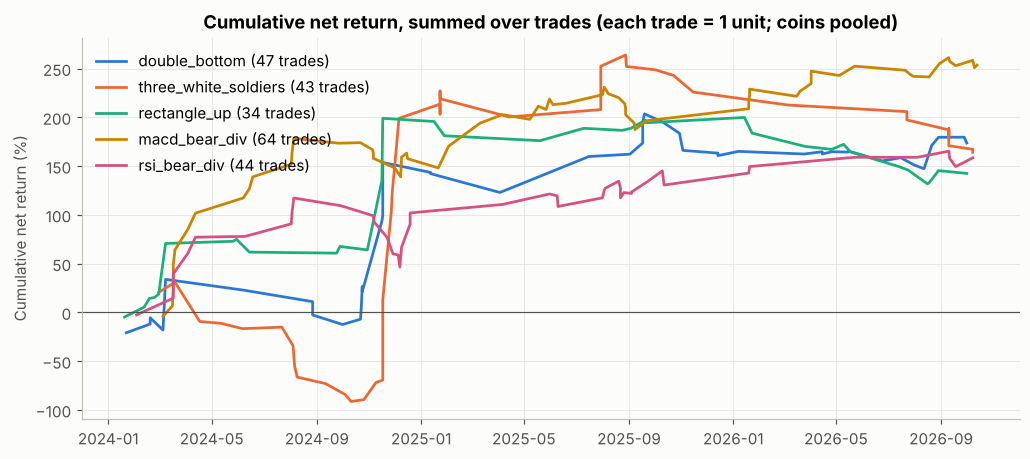

In [5]:
fig, ax = plt.subplots()
for pat, _ in PATTERNS:
    t = trades[pat]
    t = t[t['entry'] >= TEST_START].sort_values('exit')
    ax.plot(t['exit'], 100 * t['net'].cumsum(), color=COLORS[pat], label=f"{pat} ({len(t)} trades)")
ax.axhline(0, color='#52514e', lw=0.8)
ax.set_title('Cumulative net return, summed over trades (each trade = 1 unit; coins pooled)')
ax.set_ylabel('Cumulative net return (%)')
ax.legend(frameon=False, loc='upper left')
plt.show()

## 4. Is it consistent over time and across coins?

Average net return per trade (%), by year of entry, and by coin. A real edge should not come from a single year or a single coin.

In [6]:
rec = {p: t[t['entry'] >= TEST_START].copy() for p, t in trades.items()}
by_year = pd.concat({p: r.groupby(r['entry'].dt.year)['net'].agg(['mean', 'size']) for p, r in rec.items()}).unstack(0)
yr_avg = (100 * by_year['mean']).round(2)
yr_n = by_year['size'].fillna(0).astype(int)
print('Average net % per trade, by entry year (2026 is partial)')
display(yr_avg)
print('Trades per year')
display(yr_n)

Average net % per trade, by entry year (2026 is partial)


,double_bottom,three_white_soldiers,rectangle_up,macd_bear_div,rsi_bear_div
entry,,,,,
2024,9.61,10.47,14.21,6.85,5.37
2025,0.76,2.08,-0.57,1.95,1.68
2026,0.54,-5.62,-4.32,2.71,3.48


Trades per year


,double_bottom,three_white_soldiers,rectangle_up,macd_bear_div,rsi_bear_div
entry,,,,,
2024,16,19,14,23,19
2025,15,13,8,20,17
2026,16,11,12,21,8


In [7]:
by_coin = pd.DataFrame({p: 100 * r.groupby('coin')['net'].mean() for p, r in rec.items()}).round(2)
by_coin.index = [c.replace('USDT', '') for c in by_coin.index]
print('Average net % per trade, by coin, 2024 onward')
by_coin.style.background_gradient(cmap='RdBu', vmin=-8, vmax=8).format('{:.2f}')

Average net % per trade, by coin, 2024 onward


,double_bottom,three_white_soldiers,rectangle_up,macd_bear_div,rsi_bear_div
ADA,-0.53,4.81,3.41,12.13,9.69
BNB,0.93,2.39,0.26,1.61,-1.22
DOGE,11.91,-1.95,19.50,2.19,11.99
ETH,-0.46,8.95,-4.54,-0.09,-0.71
SOL,-4.54,2.33,-1.17,4.77,5.33
XRP,13.60,8.73,11.46,7.18,1.52


## 5. Do the profits survive higher costs?

Same trades, re-run with different per-side costs (fees + slippage). Small coins like DOGE and ADA can have wider spreads than 0.05%.

In [8]:
costs = [0.0, 0.00075, 0.0015, 0.003, 0.005]
rows = {}
for pat, d in PATTERNS:
    r = tuned[pat]
    stop, tgt, hold = none_if_nan(r['stop']), none_if_nan(r['tgt']), int(r['hold'])
    rows[pat] = {f'{2 * c * 100:.2f}% round trip': 100 * run_trades(coins, pat, d, stop, tgt, hold, c).query('entry >= @TEST_START')['net'].mean()
                 for c in costs}
cost_tbl = pd.DataFrame(rows).T.round(2)
print('Average net % per trade, 2024 onward')
cost_tbl

Average net % per trade, 2024 onward


,0.00% round trip,0.15% round trip,0.30% round trip,0.60% round trip,1.00% round trip
double_bottom,3.99,3.84,3.69,3.39,2.99
three_white_soldiers,4.12,3.97,3.82,3.52,3.12
rectangle_up,4.49,4.34,4.19,3.89,3.49
macd_bear_div,4.26,4.11,3.96,3.66,3.26
rsi_bear_div,3.90,3.75,3.60,3.30,2.90


## 6. Out-of-universe check: Bitcoin

Same patterns and the **same exit rules chosen on the altcoins' earlier period**, applied to Bitcoin. Bitcoin has few signals per pattern, so treat this as a sanity check only.

In [9]:
btc = prepare(['BTCUSDT'], 'daily', TEST_START, data_dir='.')
rows = []
for pat, d in PATTERNS:
    r = tuned[pat]
    t = run_trades(btc, pat, d, none_if_nan(r['stop']), none_if_nan(r['tgt']), int(r['hold']))
    for name, part in (('before 2024', t[t['entry'] < TEST_START]), ('2024 onward', t[t['entry'] >= TEST_START])):
        s = trade_stats(part)
        rows.append({'pattern': pat, 'period': name, 'trades': s['n'], 'win_rate': s['win_rate'], 'avg_net_%': s['avg_net_pct']})
pd.DataFrame(rows).pivot(index='pattern', columns='period', values=['trades', 'win_rate', 'avg_net_%']).round(2)

trades                win_rate               avg_net_%            
period               2024 onward before 2024 2024 onward before 2024 2024 onward before 2024
pattern                                                                                     
double_bottom                8.0        21.0        0.38        0.43        0.65       -1.40
macd_bear_div               17.0        35.0        0.53        0.26        1.36       -0.94
rectangle_up                 6.0        15.0        0.33        0.73       -2.66        5.41
rsi_bear_div                 9.0        18.0        0.56        0.44       -0.15       -1.20
three_white_soldiers         6.0        12.0        0.50        0.75        5.35        9.79

## Conclusions

**Headline.** After 0.30% round-trip costs, all five strategies were profitable on ETH, SOL, BNB, XRP, ADA and DOGE since 2024: **+3.6% to +4.2% per trade** on average, and each beat random entries with the same exit rules (p = 0.00–0.09). Costs barely matter here: daily trades earn about 4% each, so even a 1.0% round trip leaves +2.9% to +3.5%.

**But the edge is concentrated, and it faded for the long strategies.**

| Avg net % per trade | 2024 | 2025 | 2026 (partial) |
|---|---|---|---|
| Double bottom (long) | +9.6 | +0.8 | +0.5 |
| Three white soldiers (long) | +10.5 | +2.1 | **−5.6** |
| Rectangle breakout up (long) | +14.2 | −0.6 | **−4.3** |
| **MACD bearish divergence (short)** | +6.9 | +2.0 | **+2.7** |
| **RSI bearish divergence (short)** | +5.4 | +1.7 | **+3.5** |

- From 2025 onward, the **two short strategies are still working**: +2.3% per trade each on 41 and 25 trades, with profit factors around 1.9. The three long strategies are flat to negative (profit factor 1.2, 0.8 and 0.5).
- The long strategies' results come mostly from the late-2024 rally (the sharp jumps in the cumulative chart, mainly DOGE and XRP).
- **By coin:** MACD bearish divergence made money on 5 of 6 coins and RSI bearish divergence on 4 of 6. Double bottom and rectangle breakouts are carried by XRP and DOGE, and lose money on ETH or SOL.

**Bitcoin check (same rules, few trades):** MACD bearish divergence +1.4% per trade (17 trades), RSI bearish divergence −0.2% (9), double bottom +0.7% (8). That is weaker, and the sample is small.

**Why these numbers are probably too good**
- These five patterns were picked *because* they looked best since 2024, so 2024+ is not a clean test. Only the exit rules were tuned before 2024.
- Trades on different coins happen on the same days and are correlated, so 170 trades are fewer independent bets than they look.
- Individual trades can lose a lot: worst trades range from −10% (MACD divergence) to −40% (three white soldiers, which has no stop).
- Shorts ignore funding and borrow costs, and small coins like DOGE and ADA can have wider spreads than assumed.
- 2024 was a strong bull year for altcoins.

**Bottom line.** The most credible result is **shorting after a daily MACD or RSI bearish divergence**: profitable after costs in all three years, on most coins, with a modest +2–3% per trade recently. The long patterns (double bottom, three white soldiers, rectangle breakout) look like 2024 effects that have not continued. This is not ready for real money. The next step is to paper-trade the two short strategies going forward, because new data is the only clean out-of-sample test left.